# Repliement sur réseau : espace des conformations, énergie et bornes

**Navigation** : [↑ Bio & Médecine — sommaire de la série](../README.md) · [Structures — sommaire du pli](README.md) · feuille précédente : [Structures-01 — liaisons hydrogène et squelette protéique](Structures-01-Liaisons-Hydrogene-Squelette-Proteique-Python.ipynb) · feuille suivante : [Structures-03 — ARN circulaire et repliement en paires](Structures-03-ARN-Circulaire-Repliement-Paires-Python.ipynb)

Ce carnet est la seconde feuille du pli **Structures** de la série **Bio & Médecine**. Structures-01 décrivait une conformation ; ici, on la cherche. Dans *Crystals, Proteins, Stability and Isoperimetry*, Misha Gromov formule le repliement d'une protéine de deux façons : comme la recherche du minimum d'une énergie sur un espace de configuration, et comme une marche aléatoire biaisée par cette énergie. Le carnet joue cette double formulation sur le plus petit modèle qui la rende calculable en entier : une chaîne de trois à seize résidus sur un réseau carré, chacun hydrophobe ou polaire, dont l'énergie est l'opposé du nombre de contacts entre résidus hydrophobes.

**Objectifs d'apprentissage.** À la fin du carnet, vous savez énumérer exactement un espace de conformations et contrôler ce dénombrement ; borner le nombre de contacts d'une séquence par un argument isopérimétrique et par un argument de parité ; décrire un paysage d'énergie par ses composantes de sous-niveaux et ses minima locaux ; calculer la loi stationnaire d'une marche biaisée à temps discret et la distinguer de la loi de Gibbs ; mesurer la part des séquences qui possèdent un pli unique.

**Prérequis.** Python et `numpy` ; une marche aléatoire sur un graphe et sa loi stationnaire. La géométrie du squelette et la liaison hydrogène de Structures-01 ne servent pas ici : le modèle est plus grossier, et s'en passe.

**Durée estimée.** Une heure trente de lecture et d'exécution ; les trois exercices demandent environ une heure de plus.

Le carnet applique à cette question le contrat de méthode de la série :

1. **Modèle** — il énonce une marche qui s'évite sur le réseau carré, deux espèces de résidus, une énergie sans paramètre ajustable.
2. **Calcul** — il énumère l'espace des conformations, démontre deux bornes, résout exactement la loi stationnaire de la marche.
3. **Contrôle indépendant** — il compare chaque mesure à une voie qui ne partage ni algorithme ni formule avec la première : dénombrement sans élagage, maximum par élagage contre énumération complète, voisins retrouvés par balayage, composantes recomptées par union-find.
4. **Contre-témoin** — il construit les cas où la conclusion intuitive manque : une séquence que la parité prive de tout contact, un minimum local qui n'est pas le pli natif, une énergie nulle où la loi de la marche n'est ni uniforme ni celle de Gibbs.
5. **Statut** — il sépare ce qui est mesuré ici, ce qui est cité de Gromov, et ce qui reste ouvert.

Aucune structure expérimentale n'est lue, et aucun paramètre n'est ajusté : tout ce qui suit se déduit du modèle déclaré et de calculs exacts sur de petites tailles.


## Ce que ce carnet établit, et ce qu'il n'établit pas

| Section | Question | Contrôle indépendant | Contre-témoin |
|---|---|---|---|
| 1 | Combien y a-t-il de conformations, et combien de plis ? | Dénombrement sans élagage, par un second algorithme | La chaîne étendue, seule classe à un seul élément |
| 2 | Quel nombre de contacts peut-on atteindre, et quelles bornes le limitent ? | Maximum par élagage, contre l'énumération complète | Une séquence alternée, que la parité prive de tout contact |
| 3 | Que contient le paysage d'énergie d'une séquence ? | Voisins retrouvés par balayage, composantes recomptées par union-find | Un minimum local strict qui n'est pas le pli natif |
| 4 | Où passe la marche biaisée, et en combien de temps ? | Formule fermée contre résolution du système, trois graines | Une énergie nulle, où la loi n'est ni uniforme ni celle de Gibbs |
| 5 | Quelle part des séquences a un pli unique ? | Chaque séquence comparée à sa lecture renversée | Un pli unique n'est jamais une conformation unique : son image miroir a la même énergie |

**Ce que la feuille apporte au pli** : le passage de la conformation à l'espace des conformations. Structures-01 mesurait une chaîne donnée ; ici la chaîne est une inconnue, et la question devient ce qu'on peut affirmer d'un espace qu'on énumère en entier. Les instruments — une énergie sans paramètre, une borne démontrée, un contrôle indépendant par résultat — sont ceux qu'un algorithme de repliement devra affronter sur une protéine.

Ce carnet **n'établit pas** combien de protéines existent, ni pourquoi elles se replient vite : ces deux questions restent ouvertes dans le texte de Gromov comme dans son entretien avec Jaimungal. Il établit ce qu'un modèle très petit en dit exactement, et à quelles conditions un tel modèle peut servir de juge.


## Outils et conventions

Le carnet n'utilise que des bibliothèques standard de calcul scientifique : `numpy` pour les tableaux, `scipy.sparse` et `scipy.sparse.linalg` pour résoudre le système de la loi stationnaire, `matplotlib` pour les figures. Il ne lit aucun fichier et n'appelle aucun service.

**Le modèle déclaré.** Une chaîne de $N$ résidus est une marche qui s'évite elle-même sur le réseau carré $\mathbb{Z}^2$ : ses $N$ sites sont deux à deux distincts, et deux résidus consécutifs occupent des sites voisins. Chaque résidu est d'une seule espèce, hydrophobe $H$ ou polaire $P$, selon une **séquence** fixée. Un **contact** est une paire de résidus non consécutifs occupant des sites voisins, et l'énergie d'une conformation est l'opposé du nombre de ses contacts entre résidus $H$ :

$$E = -\,\text{nombre de contacts } H\text{–}H$$

Il n'y a aucun paramètre ajustable : ni distance, ni angle, ni poids. C'est ce qu'on appelle communément un modèle HP ; aucune publication sur ce modèle n'a été lue pour ce carnet, et aucun résultat n'y est emprunté — c'est la convention la plus simple qui réalise ce que Gromov nomme le noyau hydrophobe.

**Conformations et plis.** Une conformation est rangée dans l'ensemble $X$ en translatant son premier site à l'origine et en la tournant pour que son premier pas aille vers l'est. Un **pli** est ce qu'une conformation devient quand on regarde aussi sa réflexion dans l'axe de son premier pas : deux conformations de $X$ sont le même pli si l'une est l'image miroir de l'autre, le sens de la chaîne étant conservé.

**Paramètres déclarés.** Les tailles de chaîne, les seuils, les graines et les températures sont écrits dans le code, en tête des blocs qui les utilisent. Tout ce qui est aléatoire est semé : une exécution à l'identique rend les mêmes nombres.

**Citations.** Les passages de Gromov sont donnés en anglais, dans l'orthographe de la copie archivée.

Le premier bloc charge ces bibliothèques et fixe la taille des figures.


In [1]:
import bisect
import math

import matplotlib.pyplot as plt
import numpy as np
import scipy
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    'figure.figsize': (7.5, 4.2),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})



print(f'numpy {np.__version__} | scipy {scipy.__version__}')


numpy 2.4.6 | scipy 1.18.1


## 1. L'espace des conformations

### Ce que dit Gromov

Le texte de 2010 introduit l'espace de configuration avant d'en dire quoi que ce soit :

> Let X = X(P) be the configuration space of a given polypeptide chain P in R3 and let E ∶ X → R be the total energy ”summing up” the weak interactions between the (atoms in the) residues.

Puis il pose la question du repliement comme une question de minimum :

> Can one find the ”ground state” xmin = xfold which minimizes the energy and corresponds to the folded protein? (After all if the nature does it in a few seconds, why a mathematician can not do it?)

Dans l'entretien, il dit la même difficulté du côté du calcul :

> As you know, even folding of a protein, physically, absolutely beyond computational power of computers today and probably tomorrow, right?

Rien, dans ces trois passages, ne dit quel est cet espace $X$ ni quelle est cette fonction $E$ : ce sont des données du problème, et le texte les laisse en suspens. Le carnet doit donc choisir les siennes, et il les déclare.

*Sources : texte de 2010, p. 21 — <https://www.ihes.fr/~gromov/wp-content/uploads/2018/08/proteins-crystals-isoper.pdf> ; entretien, 00:57:44–00:57:52 — <https://www.youtube.com/watch?v=010zB6EpJYQ>.*

### Le modèle du carnet

Une chaîne de $N$ résidus est une marche qui s'évite sur le réseau carré. Le bloc qui suit énumère ces marches en fixant le premier site à l'origine et le premier pas vers l'est : c'est l'ensemble $X$ du carnet, celui où la translation et la rotation ne créent plus de doublons. Il y attache la matrice des contacts et l'énergie de la section « Outils et conventions ».


In [2]:
DIRS = ((1, 0), (-1, 0), (0, 1), (0, -1))


def enumere_marches(n):
    # Conformations d'une chaine de n residus sur le reseau carre : marches
    # qui s'evitent elles-memes, premier pas vers l'est. Ce choix fixe la
    # rotation : chaque classe de 4 conformations en a exactement une ici.
    marches, chemin, vus = [], [(0, 0), (1, 0)], {(0, 0), (1, 0)}

    def avance():
        if len(chemin) == n:
            marches.append(tuple(chemin))
            return
        x, y = chemin[-1]
        for dx, dy in DIRS:
            p = (x + dx, y + dy)
            if p in vus:
                continue
            chemin.append(p)
            vus.add(p)
            avance()
            chemin.pop()
            vus.remove(p)

    avance()
    return marches


def paires(n):
    # Couples de residus non lies par la chaine (|i - j| >= 2)
    return [(i, j) for i in range(n) for j in range(i + 2, n)]


def matrice_contacts(marches, n):
    # Une ligne par conformation, une colonne par paire : les deux residus
    # sont-ils voisins sur le reseau ?
    coords = np.array(marches, dtype=np.int64)
    adj = np.zeros((len(marches), len(paires(n))), dtype=bool)
    for q, (i, j) in enumerate(paires(n)):
        adj[:, q] = (np.abs(coords[:, i, 0] - coords[:, j, 0])
                     + np.abs(coords[:, i, 1] - coords[:, j, 1])) == 1
    return adj


def energie(adj, sequence):
    # E = moins le nombre de contacts entre residus hydrophobes H, hors chaine
    hydrophobes = {i for i, lettre in enumerate(sequence) if lettre == 'H'}
    tous_deux = np.array([i in hydrophobes and j in hydrophobes
                          for i, j in paires(len(sequence))])
    if not tous_deux.any():
        return np.zeros(adj.shape[0], dtype=np.int64)
    return -adj[:, tous_deux].sum(axis=1).astype(np.int64)


print(f'{len(enumere_marches(10))} conformations a N = 10, '
      f'{len(paires(10))} paires de residus hors chaine')


4067 conformations a N = 10, 36 paires de residus hors chaine


### La taille de $X$

À $N = 10$, le bloc précédent a trouvé $4067$ conformations, et $36$ paires de résidus non liées par la chaîne — autant de colonnes dans la matrice des contacts. Chaque pas a trois directions possibles au plus, puisque revenir en arrière est interdit, donc

$$|X| \le 3^{N-2}$$

Le bloc qui suit compte $X$ de $N = 3$ à $N = 12$ et compare chaque effectif à cette majoration.


In [3]:
print(' N    |X|    3^(N-2)   ecart   |X(N)|X(N-1)|')
for n in range(3, 13):
    nb = len(enumere_marches(n))
    naif = 3 ** (n - 2)
    print(f'{n:2d}  {nb:6d}  {naif:10d}  {naif - nb:6d}   {nb / len(enumere_marches(n - 1)):13.3f}')


 N    |X|    3^(N-2)   ecart   |X(N)|X(N-1)|
 3       3           3       0           3.000
 4       9           9       0           3.000
 5      25          27       2           2.778
 6      71          81      10           2.840
 7     195         243      48           2.746
 8     543         729     186           2.785
 9    1479        2187     708           2.724
10    4067        6561    2494           2.750


11   11025       19683    8658           2.711


12   30073       59049   28976           2.728


### Lecture du résultat

$X$ compte $3$ conformations à $N = 3$, $9$ à $N = 4$, et $30\,073$ à $N = 12$. L'écart à la majoration est nul aux deux premières tailles — trois choix de pas, puis trois fois trois, sans qu'aucune marche ne se rencontre — puis croît jusqu'à $28\,976$ à $N = 12$ : à cette taille, $X$ tient à peine plus de la moitié de $59\,049$.

La dernière colonne est le facteur par lequel $|X|$ croît d'une taille à la suivante. Il vaut $3{,}000$ tant qu'aucune marche ne se rencontre, puis oscille : $2{,}840$ à $N = 6$, $2{,}711$ à $N = 11$. Dix tailles ne suffisent pas à dire vers quoi il tend.

### Contrôle indépendant : compter sans élagage

Le dénombrement ci-dessus fixe le premier pas vers l'est et s'arrête dès qu'un site est déjà occupé. Un second algorithme, écrit sans rien reprendre du premier — une pile explicite au lieu d'une récursion, l'appartenance testée sur le chemin lui-même — énumère les marches en laissant le premier pas libre. Il doit rendre exactement quatre fois plus : quatre directions pour le premier pas, et une rotation qui transporte chaque marche sur une seule de celles de $X$. Le bloc qui suit le vérifie jusqu'à $N = 8$.


In [4]:
def compte_sans_elagage(n):
    # Toutes les marches s'evitant, premier pas libre, sans contrainte ni
    # elagage : un chemin est prolonge vers tout site non encore visite
    pile = [((0, 0),)]
    total = 0
    while pile:
        chemin = pile.pop()
        if len(chemin) == n:
            total += 1
            continue
        x, y = chemin[-1]
        for dx, dy in DIRS:
            p = (x + dx, y + dy)
            if p not in chemin:
                pile.append(chemin + (p,))
    return total


print(' N   premier pas libre   4 x |X|   egal')
for n in range(3, 9):
    brut = compte_sans_elagage(n)
    quatre_x = 4 * len(enumere_marches(n))
    print(f'{n:2d}  {brut:16d}  {quatre_x:8d}   {brut == quatre_x}')


 N   premier pas libre   4 x |X|   egal
 3                12        12   True
 4                36        36   True
 5               100       100   True
 6               284       284   True
 7               780       780   True
 8              2172      2172   True


### Lecture du contrôle

Le dénombrement sans élagage rend $12$, $36$, $100$, $284$, $780$, $2172$ marches de $3$ à $8$ sites, et la colonne de droite n'affiche que des `True` : c'est bien le quadruple de $|X|$. Les deux algorithmes ne partagent ni leur structure — récursion contre pile — ni leur contrainte — premier pas fixé contre premier pas libre.

### Les plis

Le texte de Gromov nomme un état replié, $x_{\min} = x_{\text{fold}}$, et non deux. Le carnet appelle **pli** une classe pour les huit isométries du réseau : quatre rotations autour du premier site, et leurs composées avec la réflexion qui échange les deux côtés du premier pas. Le sens de la chaîne y est conservé. Deux conformations d'un même pli ont la même énergie, puisqu'elles ont les mêmes contacts. Le bloc qui suit numérote ces classes et compte leur taille, de $N = 4$ à $N = 12$.


In [5]:
def identifiants_plis(marches):
    # Un pli = une classe pour les 8 isometries du reseau carre (4 rotations,
    # 2 reflexions), le sens de la chaine conserve. Chaque classe recoit un
    # numero ; deux conformations d'une meme classe ont la meme energie.
    cles, ids = {}, np.zeros(len(marches), dtype=np.int64)
    for k, w in enumerate(marches):
        images = []
        for reflexion in (False, True):
            pts = [(x, -y) for x, y in w] if reflexion else list(w)
            for _ in range(4):
                pts = [(-y, x) for x, y in pts]      # quart de tour autour de l'origine
                images.append(tuple(pts))
        cle = min(images)
        if cle not in cles:
            cles[cle] = len(cles)
        ids[k] = cles[cle]
    return ids


print(' N    |X|    plis   |X| / plis   tailles de classe (taille x nombre)')
for n in range(4, 13):
    marches = enumere_marches(n)
    ids = identifiants_plis(marches)
    effectifs = np.bincount(ids)
    histogramme = np.bincount(effectifs)
    texte = ', '.join(f'{t} x {histogramme[t]}' for t in range(len(histogramme)) if histogramme[t])
    print(f'{n:2d}  {len(marches):6d}  {len(effectifs):6d}   {len(marches) / len(effectifs):10.4f}   {texte}')


 N    |X|    plis   |X| / plis   tailles de classe (taille x nombre)
 4       9       5       1.8000   1 x 1, 2 x 4
 5      25      13       1.9231   1 x 1, 2 x 12
 6      71      36       1.9722   1 x 1, 2 x 35
 7     195      98       1.9898   1 x 1, 2 x 97
 8     543     272       1.9963   1 x 1, 2 x 271
 9    1479     740       1.9986   1 x 1, 2 x 739


10    4067    2034       1.9995   1 x 1, 2 x 2033


11   11025    5513       1.9998   1 x 1, 2 x 5512


12   30073   15037       1.9999   1 x 1, 2 x 15036


### Lecture du résultat

La dernière colonne se lit, à chaque taille, « $1 \times 1$, $2 \times \dots$ » : une classe d'un seul élément, et des classes de deux. La classe d'un seul élément est la chaîne étendue, qui est sa propre image miroir. Toutes les autres classes en ont deux, donc

$$|X| = 2 \times (\text{nombre de plis}) - 1$$

que vérifie chaque ligne : $9 = 2 \times 5 - 1$ à $N = 4$, et $30\,073 = 2 \times 15\,037 - 1$ à $N = 12$.

**Conséquence pour toute la suite.** Un pli unique n'est jamais une conformation unique : il est toujours réalisé par deux conformations, images l'une de l'autre. Chercher le pli d'une séquence, c'est donc chercher une paire.

Le bloc qui suit trace, à $N = 10$, une conformation de $X$, son image miroir, et la chaîne étendue. Les numéros portent le rang de chaque résidu dans la chaîne : ils montrent que le sens de la chaîne est le même dans les deux premiers panneaux.


classes de taille 1 : 1 - ((0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0))
une classe de taille 2 : ((0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (-1, 2), (-2, 2), (-2, 1))
                       ((0, 0), (1, 0), (2, 0), (2, -1), (2, -2), (1, -2), (0, -2), (-1, -2), (-2, -2), (-2, -1))


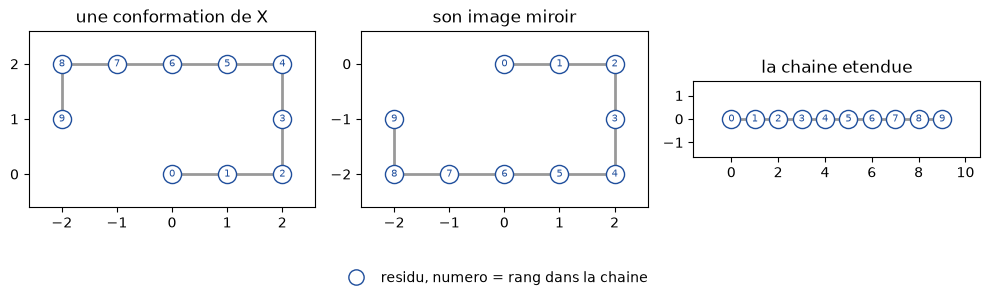

In [6]:
def dessine(marche, sequence, ax, titre='', numeros=False):
    # Trace la chaine : residus H pleins, P vides, contacts H-H en pointille
    xs, ys = zip(*marche)
    ax.plot(xs, ys, color='0.6', lw=2, zorder=1)
    for i, (x, y) in enumerate(marche):
        hydrophobe = sequence[i] == 'H'
        ax.scatter(x, y, s=170, facecolor='#1f4e9c' if hydrophobe else 'white',
                   edgecolor='#1f4e9c', zorder=3)
        if numeros:
            ax.annotate(str(i), (x, y), color='white' if hydrophobe else '#1f4e9c',
                        ha='center', va='center', fontsize=7, zorder=4)
    rang = {p: i for i, p in enumerate(marche)}
    for i, (x, y) in enumerate(marche):
        if sequence[i] != 'H':
            continue
        for dx, dy in DIRS:
            j = rang.get((x + dx, y + dy))
            if j is not None and j > i + 1 and sequence[j] == 'H':
                ax.plot((x, x + dx), (y, y + dy), color='#c0392b', ls='--', lw=1.2, zorder=2)
    # Meme echelle sur les deux axes ; une chaine etendue recoit une marge verticale
    # pour que son panneau ne soit pas aplati en une bande
    marge = max(0.6, 0.18 * (max(xs) - min(xs)) - 0.5 * (max(ys) - min(ys)))
    ax.set_xlim(min(xs) - marge, max(xs) + marge)
    ax.set_ylim(min(ys) - marge, max(ys) + marge)
    ax.set_aspect('equal')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(titre)
    ax.grid(False)


def legende_residus(fig, hydrophobes=True, contacts=True):
    # Legende sous la figure, et place reservee pour elle : cercle plein = residu
    # hydrophobe H, cercle vide = residu polaire P, pointille rouge = contact H-H
    poignees = []
    if hydrophobes:
        poignees.append(Line2D([], [], marker='o', ls='', markersize=11, markerfacecolor='#1f4e9c',
                               markeredgecolor='#1f4e9c', label='residu hydrophobe H'))
        poignees.append(Line2D([], [], marker='o', ls='', markersize=11, markerfacecolor='white',
                               markeredgecolor='#1f4e9c', label='residu polaire P'))
    else:
        poignees.append(Line2D([], [], marker='o', ls='', markersize=11, markerfacecolor='white',
                               markeredgecolor='#1f4e9c', label='residu, numero = rang dans la chaine'))
    if contacts:
        poignees.append(Line2D([], [], color='#c0392b', ls='--', lw=1.2, label='contact H-H hors chaine'))
    fig.legend(handles=poignees, loc='lower center', ncol=len(poignees), frameon=False)
    plt.tight_layout(rect=(0, 0.1, 1, 1))


marches_10 = enumere_marches(10)
ids_10 = identifiants_plis(marches_10)
classes = {}
for i, f in enumerate(ids_10):
    classes.setdefault(int(f), []).append(i)
seule = [m for m, membres in classes.items() if len(membres) == 1]
deux = [m for m, membres in classes.items() if len(membres) == 2]
a, b = classes[deux[600]]
print('classes de taille 1 :', len(seule), '-', marches_10[classes[seule[0]][0]])
print('une classe de taille 2 :', marches_10[a])
print('                      ', marches_10[b])

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
dessine(marches_10[a], 'P' * 10, axes[0], 'une conformation de X', numeros=True)
dessine(marches_10[b], 'P' * 10, axes[1], 'son image miroir', numeros=True)
dessine(marches_10[classes[seule[0]][0]], 'P' * 10, axes[2], 'la chaine etendue', numeros=True)
legende_residus(fig, hydrophobes=False, contacts=False)
plt.show()

### Lecture de la figure

Les deux premiers panneaux se lisent comme une phrase et son reflet dans un miroir horizontal : mêmes rangs aux mêmes abscisses, ordonnées opposées. Le troisième panneau est la chaîne étendue, la seule conformation de $X$ qui coïncide avec son image miroir.

### En résumé

| Grandeur | Valeur à $N = 10$ | Contrôle |
|---|---|---|
| Conformations de $X$ | $4067$ | $2172 = 4 \times 543$ à $N = 8$, par le dénombrement sans élagage |
| Facteur de croissance | $2{,}750$ | — |
| Plis | $2034$ | $4067 = 2 \times 2034 - 1$ |
| Conformations par pli | $2$, sauf la chaîne étendue | classes de taille $1 \times 1$ et $2 \times 2033$ |

La dernière ligne est le contre-témoin de la section : le modèle ne dit pas « un pli, une conformation », et toute mesure qui confondrait les deux serait fausse dès $N = 4$.


## 2. L'énergie et les deux bornes

### Ce que dit Gromov

Ce qui tient la chaîne repliée est décrit ainsi :

> Immediately upon polymerization, a polypeptide chain … ”folds” into a specific rather compact shape, called protein, held by additional weak binding forces between residues, mainly by hydrophobicity ”pressure” and hydrogen bonds. (Seven out of 20 amino acids, e.g. tryptophan and cysteine, are rather hydrophobic. They tend to conglomerate in the protein hydrophobic core with small exposure to the surrounding water.)

Et l'énergie n'est pas une somme de termes de paire :

> The total interaction energy E of a polypeptide is not the sum of the pairwise residue interaction energies.

Le carnet garde pourtant une énergie additive, parce qu'elle rend les bornes démontrables ; c'est une simplification déclarée, que la section 6 range parmi les limites.

*Sources : texte de 2010, p. 14 et p. 24 — <https://www.ihes.fr/~gromov/wp-content/uploads/2018/08/proteins-crystals-isoper.pdf>.*

### La borne isopérimétrique

Soit $C$ le nombre de couples de sites voisins d'une conformation, liaisons de la chaîne comprises. Centrons un carré unité sur chaque site : deux carrés de sites voisins partagent un côté, donc le contour de la réunion des $N$ carrés a pour longueur $p = 4N - 2C$. Notons $W$ et $H$ les nombres de colonnes et de rangées occupées par cette réunion. Dans chaque colonne, le carré le plus haut et le carré le plus bas apportent chacun un côté horizontal au contour ; dans chaque rangée, le carré le plus à gauche et le carré le plus à droite apportent chacun un côté vertical. Donc

$$p \ge 2(W + H) \ge 4\sqrt{WH} \ge 4\sqrt{N}$$

la dernière inégalité venant de ce que les $N$ carrés se répartissent dans $WH$ cases. Comme la chaîne compte $N - 1$ liaisons, les contacts hors chaîne sont au nombre de

$$c = C - (N - 1) = N + 1 - \frac{p}{2} \le N + 1 - (W + H) \le N + 1 - 2\sqrt{N}$$

Pour une séquence qui compte $k$ résidus hydrophobes, le même argument vaut pour la réunion de leurs $k$ carrés, qu'elle soit connexe ou non : son contour a pour longueur $p_H = 4k - 2(h_a + c)$, où $h_a$ est le nombre de liaisons $H$–$H$ de la chaîne et $c$ le nombre de contacts, et il vaut au moins $4\sqrt{k}$. Donc

$$c \le 2k - h_a - 2\sqrt{k}$$

### La borne de parité

Le réseau carré est un damier : deux sites voisins sont de couleurs opposées, et la couleur du site occupé par un résidu est la parité de son rang. Un contact unit donc un résidu $H$ de rang pair et un résidu $H$ de rang impair. Si $k_e$ et $k_o$ en sont les nombres, les paires possibles sont au nombre de $k_e k_o$, dont il faut ôter les $h_a$ liaisons $H$–$H$ de la chaîne :

$$c \le k_e k_o - h_a$$

Le carnet retient la plus petite des deux bornes. Le bloc qui suit cherche le maximum exact d'une chaîne tout hydrophobe, avec et sans élagage, et le compare au plancher de la borne isopérimétrique.


 N    borne N + 1 - 2 V(N)   plancher   avec elagage   sans elagage   atteint
 4              1.0000          1              1              1   True
 5              1.5279          1              1              1   True
 6              2.1010          2              2              2   True
 7              2.7085          2              2              2   True
 8              3.3431          3              3              3   True
 9              4.0000          4              4              4   True
10              4.6754          4              4              4   True
11              5.3668          5              5              5   True


12              6.0718          6              6              6   True
13              6.7889          6              6              -   True


14              7.5167          7              7              -   True


15              8.2540          8              8              -   True


16              9.0000          9              9              -   True


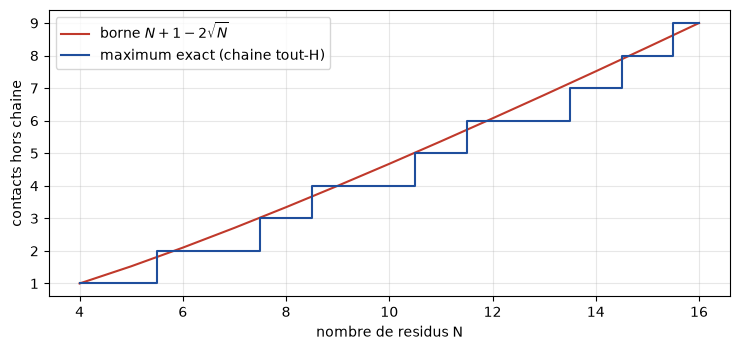

In [7]:
def contacts_maximum(n):
    # Nombre maximal de contacts hors chaine d'une chaine tout-H de n residus :
    # recherche complete avec elagage. Un site ajoute touche au plus 3 sites
    # deja poses, son precedent ne comptant pas ; si meme cette majoration ne
    # peut plus battre le record, la branche est abandonnee.
    record = [0]
    chemin, vus = [(0, 0), (1, 0)], {(0, 0), (1, 0)}

    def avance(c):
        if len(chemin) == n:
            record[0] = max(record[0], c)
            return
        if c + 3 * (n - len(chemin)) <= record[0]:
            return
        x, y = chemin[-1]
        for dx, dy in DIRS:
            p = (x + dx, y + dy)
            if p in vus:
                continue
            ajout = sum((p[0] + ex, p[1] + ey) in vus
                        for ex, ey in DIRS if (p[0] + ex, p[1] + ey) != (x, y))
            chemin.append(p)
            vus.add(p)
            avance(c + ajout)
            chemin.pop()
            vus.remove(p)

    avance(0)
    return record[0]


tailles, maxima, bornes = [], [], []
print(' N    borne N + 1 - 2 V(N)   plancher   avec elagage   sans elagage   atteint')
for n in range(4, 17):
    borne = n + 1 - 2 * math.sqrt(n)
    cmax = contacts_maximum(n)
    direct = int(matrice_contacts(enumere_marches(n), n).sum(axis=1).max()) if n <= 12 else None
    print(f'{n:2d}   {borne:17.4f}   {math.floor(borne):8d}   {cmax:12d}   '
          f'{direct if direct is not None else "-":>12}   {cmax == math.floor(borne)}')
    tailles.append(n)
    maxima.append(cmax)
    bornes.append(borne)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(tailles, bornes, color='#c0392b', label=r'borne $N + 1 - 2\sqrt{N}$')
ax.step(tailles, maxima, where='mid', color='#1f4e9c', label='maximum exact (chaine tout-H)')
ax.set_xlabel('nombre de residus N')
ax.set_ylabel('contacts hors chaine')
ax.legend()
plt.tight_layout()
plt.show()


### Lecture du résultat

La borne isopérimétrique est un nombre réel, $N + 1 - 2\sqrt{N}$ ; le nombre de contacts est entier, donc inférieur ou égal au plancher de la borne. Or le maximum exact atteint ce plancher de $N = 4$ à $N = 16$, sans exception. Aux tailles $4$, $9$ et $16$, la borne vaut exactement $1{,}0000$, $4{,}0000$ et $9{,}0000$, et le maximum la rejoint : la chaîne forme un carré. Jusqu'à $N = 12$, l'énumération complète de $X$ rend le même maximum. La figure porte la borne en rouge et le maximum exact en bleu : l'une est une courbe, l'autre un escalier qui reste en dessous et la rejoint aux tailles $4$, $9$ et $16$.

### Où se trouvent les conformations compactes ?

Une **boîte** est le plus petit rectangle, à côtés portés par le réseau, qui contient une conformation. La borne dépend de la conformation seulement par la somme des côtés de sa boîte : $N + 1 - (W + H)$. Le bloc qui suit range les conformations de contacts maximum selon leur boîte, à $N = 10$, $11$ et $12$, puis range de même tout $X$ à $N = 12$.


In [8]:
def boite(marche):
    # Plus petit rectangle, cotes sur le reseau, contenant la conformation
    xs, ys = zip(*marche)
    return max(xs) - min(xs) + 1, max(ys) - min(ys) + 1


marches_12 = enumere_marches(12)
adj_12 = matrice_contacts(marches_12, 12)
for n, marches, contacts_n in ((10, marches_10, matrice_contacts(marches_10, 10).sum(axis=1)),
                               (11, enumere_marches(11), None),
                               (12, marches_12, adj_12.sum(axis=1))):
    if contacts_n is None:
        contacts_n = matrice_contacts(marches, n).sum(axis=1)
    hauts = np.where(contacts_n == contacts_n.max())[0]
    formes = {}
    for i in hauts:
        petit, grand = sorted(boite(marches[i]))
        formes[(petit, grand)] = formes.get((petit, grand), 0) + 1
    print(f'N = {n}, chaine tout-H : {len(hauts)} conformations a {int(contacts_n.max())} contacts, '
          f'boites (petit cote, grand cote) : {sorted(formes.items())}')
print('N = 12 : nombre de conformations par boite (petit cote, grand cote), les plus frequentes :')
repertoire = {}
for w in marches_12:
    petit, grand = sorted(boite(w))
    repertoire[(petit, grand)] = repertoire.get((petit, grand), 0) + 1
print(sorted(repertoire.items(), key=lambda kv: -kv[1])[:10])


N = 10, chaine tout-H : 196 conformations a 4 contacts, boites (petit cote, grand cote) : [((2, 5), 22), ((3, 4), 174)]
N = 11, chaine tout-H : 96 conformations a 5 contacts, boites (petit cote, grand cote) : [((3, 4), 96)]
N = 12, chaine tout-H : 62 conformations a 6 contacts, boites (petit cote, grand cote) : [((3, 4), 62)]
N = 12 : nombre de conformations par boite (petit cote, grand cote), les plus frequentes :
[((4, 5), 4084), ((4, 6), 3868), ((5, 6), 3312), ((4, 7), 2818), ((5, 5), 2212), ((3, 7), 1900), ((3, 6), 1770), ((5, 7), 1488), ((3, 8), 1456), ((4, 4), 1064)]


### Lecture du résultat

À $N = 10$, $196$ conformations atteignent $4$ contacts : $22$ dans une boîte $2 \times 5$, $174$ dans une boîte $3 \times 4$. Les deux boîtes ont la même somme de côtés, $7$, donc la même borne, $11 - 7 = 4$ : la contrainte porte sur cette somme, pas sur la forme. À $N = 11$ et à $N = 12$, toutes les conformations de contacts maximum tiennent dans une boîte $3 \times 4$.

La dernière ligne du bloc range cette fois tout $X$ à $N = 12$. La boîte la plus fréquente y est $4 \times 5$, avec $4084$ conformations : une conformation prise au hasard dans $X$ n'est en général pas dans la boîte la plus compacte.

### Les deux bornes, séquence par séquence

À $N = 10$, il y a $2^{10} = 1024$ séquences. Le bloc qui suit calcule, pour chacune, son maximum de contacts sur $X$ tout entier et le compare aux deux bornes, nombre d'hydrophobes par nombre d'hydrophobes.


In [9]:
def bornes(sequence):
    # Bornes du nombre de contacts H-H d'une sequence : isoperimetrique (le
    # noyau hydrophobe tient dans la plus petite boite possible) et de parite
    # (le reseau est un damier : deux residus voisins sont de parites opposees)
    k = sequence.count('H')
    liaison_hh = sum(sequence[i] == 'H' and sequence[i + 1] == 'H' for i in range(len(sequence) - 1))
    k_pair = sum(sequence[i] == 'H' for i in range(0, len(sequence), 2))
    return 2 * k - liaison_hh - 2 * math.sqrt(k), k_pair * (k - k_pair) - liaison_hh


def en_sequence(seq, n):
    # Ecriture d'une sequence numerotee par un entier : le bit de rang i dit si
    # le residu i est hydrophobe
    return ''.join('H' if seq >> i & 1 else 'P' for i in range(n))


SEQUENCE_10 = 'HHPHPPHPPH'
SEQUENCE_12 = 'HHHPHPPHPPHP'

adj_10 = matrice_contacts(marches_10, 10)
print('N = 10, 1024 sequences : contacts maximum contre les deux bornes')
print('  k   sequences   depasse iso   depasse par   atteint iso   atteint par   '
      'atteint la borne basse   aucun contact')
for k in range(11):
    compteurs = [0] * 7
    for seq in range(1024):
        sequence = en_sequence(seq, 10)
        if sequence.count('H') != k:
            continue
        iso, par = bornes(sequence)
        cmax = int(-energie(adj_10, sequence).min())
        compteurs[0] += 1
        compteurs[1] += cmax > iso + 1e-9
        compteurs[2] += cmax > par + 1e-9
        compteurs[3] += cmax == math.floor(iso + 1e-9)
        compteurs[4] += cmax == math.floor(par + 1e-9)
        compteurs[5] += cmax == math.floor(min(iso, par) + 1e-9)
        compteurs[6] += cmax == 0
    print(f'{k:3d}   {compteurs[0]:9d}   {compteurs[1]:11d}   {compteurs[2]:11d}   '
          f'{compteurs[3]:11d}   {compteurs[4]:11d}   {compteurs[5]:23d}   {compteurs[6]:13d}')
for sequence in (SEQUENCE_10, 'HPHPHPHPHP', 'HHHHHHHHHH'):
    iso, par = bornes(sequence)
    print(f'{sequence} : k = {sequence.count("H")}, borne isoperimetrique {iso:.4f}, '
          f'borne de parite {par}, maximum mesure {int(-energie(adj_10, sequence).min())}')


N = 10, 1024 sequences : contacts maximum contre les deux bornes
  k   sequences   depasse iso   depasse par   atteint iso   atteint par   atteint la borne basse   aucun contact
  0           1             0             0             1             1                         1               1
  1          10             0             0            10            10                        10              10
  2          45             0             0            25            45                        45              29
  3         120             0             0           100           120                       120              28
  4         210             0             0            52           154                       154              10
  5         252             0             0           154            34                       188               2
  6         210             0             0            39             0                        39               0
  7         120         

  8          45             0             0            16             0                        16               0
  9          10             0             0             2             0                         2               0
 10           1             0             0             1             0                         1               0
HHPHPPHPPH : k = 5, borne isoperimetrique 4.5279, borne de parite 5, maximum mesure 4
HPHPHPHPHP : k = 5, borne isoperimetrique 5.5279, borne de parite 0, maximum mesure 0
HHHHHHHHHH : k = 10, borne isoperimetrique 4.6754, borne de parite 16, maximum mesure 4


### Lecture du résultat

Les deux colonnes « dépasse » sont nulles de la première à la dernière ligne : aucune des $1024$ séquences ne viole une borne.

La borne de parité est la plus contraignante tant que les résidus hydrophobes sont peu nombreux : jusqu'à $k = 3$, toutes les séquences l'atteignent, $10$ sur $10$, $45$ sur $45$ puis $120$ sur $120$. À $k = 4$, $154$ séquences sur $210$ atteignent la parité et $52$ l'isopérimétrie ; à $k = 5$, elles sont $34$ et $154$ sur $252$. À partir de $k = 6$, plus aucune n'atteint la parité, alors que $39$ d'entre elles atteignent encore le plancher de la borne isopérimétrique : quand les hydrophobes deviennent nombreux, c'est la géométrie qui limite.

Les trois dernières lignes montrent les cas extrêmes. La séquence alternée `HPHPHPHPHP` a une borne de parité nulle, et ne forme en effet aucun contact. La chaîne tout hydrophobe est limitée par la borne isopérimétrique, $4{,}6754$, et sa borne de parité, $16$, ne dit rien. La séquence `HHPHPPHPPH` a pour bornes $4{,}5279$ et $5$ : au plus $4$ contacts, et elle en a $4$.

### Exercice 1 — la borne est-elle atteinte boîte par boîte ?

Pour une chaîne tout hydrophobe contenue dans une boîte de côtés $W$ et $H$, la démonstration de la section donne la borne $N + 1 - (W + H)$. À $N = 12$, toutes les conformations de contacts maximum tiennent dans la boîte $3 \times 4$. Qu'en est-il des autres boîtes ?

**À faire.** Pour les boîtes $3 \times 4$, $2 \times 6$ et $1 \times 12$, à $N = 12$ : calculer la borne, puis le maximum mesuré sur les conformations de $X$ dont la boîte est exactement celle-là.

**Indice.** `boite(marche)` rend les deux côtés d'une conformation ; `marches_12` et `adj_12` sont l'espace $X$ et sa matrice des contacts à $N = 12$ ; le nombre de contacts d'une conformation est la somme de sa ligne. La boîte $1 \times 12$ ne contient qu'une seule conformation.

**Étape 1.** Écrire `contacts_maximum_en_boite(n, largeur, hauteur)`, qui renvoie la borne puis le maximum mesuré.
**Étape 2.** L'appliquer aux trois boîtes.
**Étape 3.** Conclure : la borne est-elle atteinte dans chaque boîte, et que dit le cas de la boîte $1 \times 12$ ?


In [10]:
def contacts_maximum_en_boite(n, largeur, hauteur):
    # TODO etudiant : renvoyez la borne de contacts d'une chaine tout-H de n
    # residus contenue dans une boite largeur x hauteur, puis le maximum mesure
    # sur les conformations de X dont la boite est exactement celle-la (etape 1)
    return None


# Etape 2 : appliquer aux trois boites de N = 12 ; etape 3 : comparer
for largeur, hauteur in ((3, 4), (2, 6), (1, 12)):
    resultat = contacts_maximum_en_boite(12, largeur, hauteur)
    if resultat is None:
        print(f'boite {largeur} x {hauteur} : exercice a completer')
    else:
        print(f'boite {largeur} x {hauteur} : borne {resultat[0]}, maximum mesure {resultat[1]}')


boite 3 x 4 : exercice a completer
boite 2 x 6 : exercice a completer
boite 1 x 12 : exercice a completer


### En résumé

| Ce qui est établi | Valeur | Contrôle indépendant |
|---|---|---|
| Maximum d'une chaîne tout hydrophobe | plancher de $N + 1 - 2\sqrt{N}$, de $N = 4$ à $N = 16$ | énumération complète de $X$, même maximum jusqu'à $N = 12$ |
| Boîte des conformations de contacts maximum | $3 \times 4$ à $N = 11$ et $N = 12$ | — |
| Bornes d'une séquence à $N = 10$ | $2k - h_a - 2\sqrt{k}$ et $k_e k_o - h_a$ | $1024$ maximums mesurés, aucun dépassement |

Le contre-témoin de la section est la séquence alternée : une borne de parité nulle, qu'aucune géométrie ne relève, et un maximum nul en retour.


## 3. Le paysage

### Ce que dit Gromov

Le minimum seul ne suffit pas, et le texte dit pourquoi :

> But E may have lots of local minima: their number is likely to grow exponentially with the dimension of X that is (roughly) proportional to the number N of residues in P. If so, a protein can not fold reasonably fast, if at all, for most E.

Et même un minimum unique ne suffirait pas :

> … may have many connected componets spread over X and not localized at all around any xfold. And even if U(ε) is localized, the time of arrival to it from a ”random” x ∈ X may be too long. There must be something special about E which allows (fast) folding.

*Sources : texte de 2010, p. 21–23 — <https://www.ihes.fr/~gromov/wp-content/uploads/2018/08/proteins-crystals-isoper.pdf>.*

Le carnet reprend ces trois objets — minima locaux, composantes des sous-niveaux, temps d'arrivée — et les mesure sur sa séquence.

### Les mouvements

Le paysage a besoin d'une notion de déplacement élémentaire dans $X$. Le carnet en retient deux, qui changent un seul site : le **déplacement d'extrémité**, qui porte une extrémité sur un site libre voisin de son appui, et le **retournement de coude**, qui fait passer le site du milieu d'un coude de l'autre côté du segment formé par ses deux voisins. Le résultat est remis dans $X$ — translation, puis rotation du premier pas vers l'est — avant d'être cherché dans la liste des conformations. Le bloc qui suit construit ce graphe à $N = 8$, $10$ et $12$.


In [11]:
def forme_canonique(chemin):
    # Representant dans X d'une conformation : translation (premier site a
    # l'origine) puis rotation (premier pas vers l'est). Deplacer la premiere
    # extremite ou retourner le premier coude peut changer la direction du
    # premier pas : le mouvement n'est pas perdu pour autant.
    ox, oy = chemin[0]
    pts = [(x - ox, y - oy) for x, y in chemin]
    dx, dy = pts[1]
    if (dx, dy) == (0, 1):
        pts = [(y, -x) for x, y in pts]
    elif (dx, dy) == (-1, 0):
        pts = [(-x, -y) for x, y in pts]
    elif (dx, dy) == (0, -1):
        pts = [(-y, x) for x, y in pts]
    return tuple(pts)


def candidats(marche, extremites=True):
    # Deplacements d'une extremite vers un site libre voisin de son appui, et
    # retournements d'un coude : le site du milieu passe de l'autre cote du
    # segment forme par ses deux voisins de chaine
    n = len(marche)
    vus = set(marche)
    sorties = []
    if extremites:
        for bout, appui in ((0, marche[1]), (n - 1, marche[n - 2])):
            x, y = appui
            for dx, dy in DIRS:
                p = (x + dx, y + dy)
                if p not in vus:
                    c = list(marche)
                    c[bout] = p
                    sorties.append(tuple(c))
    for i in range(1, n - 1):
        (ax, ay), (bx, by), (cx, cy) = marche[i - 1], marche[i], marche[i + 1]
        p = (ax + cx - bx, ay + cy - by)
        if p != (bx, by) and p not in vus:
            c = list(marche)
            c[i] = p
            sorties.append(tuple(c))
    return sorties


def graphe_des_mouvements(marches, extremites=True):
    # Listes d'adjacence : y est voisin de x s'il s'obtient par un mouvement,
    # lu dans X apres remise en forme canonique
    index = {w: i for i, w in enumerate(marches)}
    return [sorted({index[forme_canonique(c)] for c in candidats(w, extremites)})
            for w in marches]


def composantes(voisins):
    # Composantes connexes d'un graphe donne par listes d'adjacence, par
    # union-find ; la plus grande est renvoyee en premier
    parent = list(range(len(voisins)))

    def racine(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for x in range(len(voisins)):
        for y in voisins[x]:
            ra, rb = racine(x), racine(y)
            if ra != rb:
                parent[ra] = rb
    groupes = {}
    for x in range(len(voisins)):
        groupes.setdefault(racine(x), []).append(x)
    return sorted(groupes.values(), key=len, reverse=True)


print(' N     |X|   aretes   degre moyen   degre mini   degre maxi   composantes   '
      'sans mouvement   symetrique')
for n in (8, 10, 12):
    marches = marches_10 if n == 10 else enumere_marches(n)
    voisins_n = graphe_des_mouvements(marches)
    aretes = sum(len(v) for v in voisins_n) // 2
    degres = [len(v) for v in voisins_n]
    symetrique = all(x in voisins_n[y] for x in range(len(marches)) for y in voisins_n[x])
    print(f'{n:2d}  {len(marches):6d}  {aretes:7d}   {2 * aretes / len(marches):11.2f}   '
          f'{min(degres):10d}   {max(degres):10d}   {len(composantes(voisins_n)):13d}   '
          f'{degres.count(0):14d}   {symetrique}')


 N     |X|   aretes   degre moyen   degre mini   degre maxi   composantes   sans mouvement   symetrique
 8     543     1634          6.02            2           10               1                0   True


10    4067    13674          6.72            2           12               1                0   True


12   30073   111982          7.45            1           14               1                0   True


### Lecture du résultat

Le graphe des mouvements est connexe aux trois tailles : ses $543$, $4067$ et $30\,073$ états tiennent dans une seule composante, et aucun n'est sans mouvement. Le degré moyen passe de $6{,}02$ à $7{,}45$ ; la dernière colonne vérifie que la relation de voisinage est symétrique.

### Le paysage d'une séquence

La suite du carnet étudie une seule séquence, `HHPHPPHPPH`, dite **séquence déclarée**. La section 2 a montré que ses contacts ne dépassent pas $4$. Le bloc qui suit calcule l'énergie de toutes les conformations de $X$ pour cette séquence, compte les conformations par niveau d'énergie, et, de $E^*$ à $0$, le nombre de composantes de l'ensemble des états d'énergie au plus $t$. Il relève aussi les **minima locaux stricts** : les états dont tous les voisins sont d'énergie strictement plus grande.


sequence HHPHPPHPPH : E* = -4, 2 conformations natives, 1 pli natif


energies de E* a 0        : [-4, -3, -2, -1, 0]
conformations par energie : [2, 22, 276, 1440, 2327]
seuil t                   : [-4, -3, -2, -1, 0]
etats d energie <= t      : [2, 24, 300, 1740, 4067]
composantes de E <= t     : [2, 24, 92, 3, 1]
minima locaux stricts     : 92 , par profondeur : [2, 22, 66, 2]
un minimum local strict : 3 contacts, boite [3, 4]


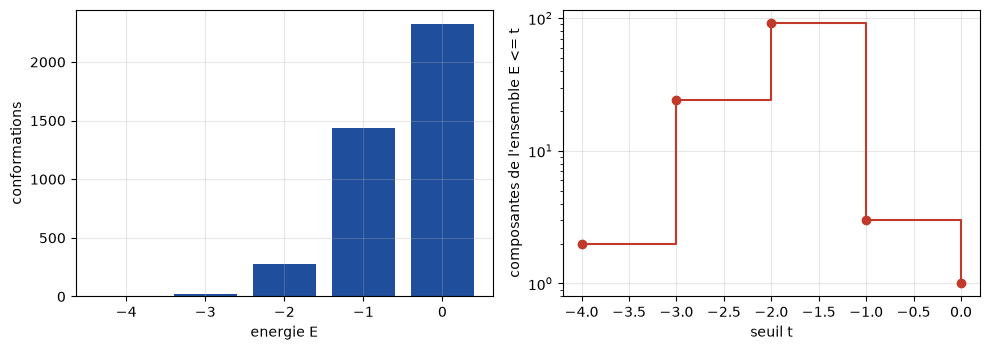

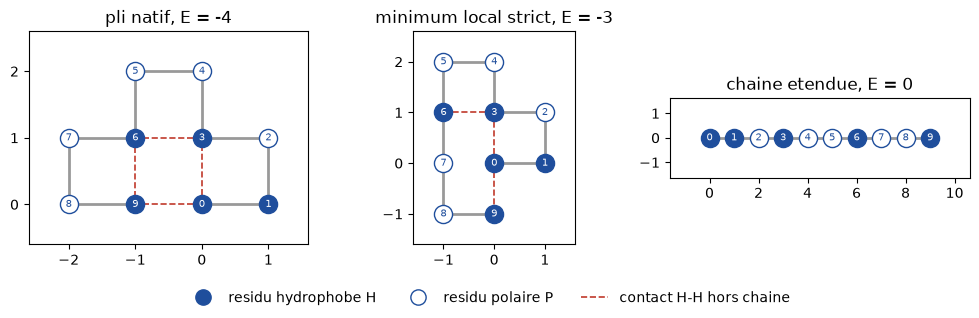

In [12]:
e = energie(adj_10, SEQUENCE_10)
voisins = graphe_des_mouvements(marches_10)
natives = np.where(e == e.min())[0]
print(f'sequence {SEQUENCE_10} : E* = {int(e.min())}, {len(natives)} conformations natives, '
      f'{len(set(ids_10[natives].tolist()))} pli natif')


def sous_niveaux(e, voisins):
    # Pour chaque seuil t : nombre d'etats d'energie au plus t, et nombre de
    # composantes de cet ensemble, compte par parcours en profondeur
    lignes = []
    for t in range(int(e.min()), 1):
        vus = np.zeros(len(e), dtype=bool)
        nb = 0
        for s in np.where(e <= t)[0]:
            if vus[s]:
                continue
            nb += 1
            pile = [s]
            vus[s] = True
            while pile:
                v = pile.pop()
                for w in voisins[v]:
                    if not vus[w] and e[w] <= t:
                        vus[w] = True
                        pile.append(w)
        lignes.append((t, int((e <= t).sum()), nb))
    return lignes


def minima_locaux(e, voisins):
    # Indices des minima locaux stricts : tous leurs voisins sont d'energie
    # strictement superieure
    return [x for x in range(len(e))
            if voisins[x] and all(e[y] > e[x] for y in voisins[x])]


niveaux = sous_niveaux(e, voisins)
stricts = minima_locaux(e, voisins)
profondeurs = np.array([e[x] - e.min() for x in stricts], dtype=np.int64)
print('energies de E* a 0        :', list(range(int(e.min()), 1)))
print('conformations par energie :', np.bincount(-e).tolist()[::-1])
print('seuil t                   :', [l[0] for l in niveaux])
print('etats d energie <= t      :', [l[1] for l in niveaux])
print('composantes de E <= t     :', [l[2] for l in niveaux])
print('minima locaux stricts     :', len(stricts), ', par profondeur :', np.bincount(profondeurs).tolist())
profondeur_1 = [x for x in stricts if e[x] == e.min() + 1] or stricts
exemple = profondeur_1[len(profondeur_1) // 2]
print(f'un minimum local strict : {-int(e[exemple])} contacts, boite {sorted(boite(marches_10[exemple]))}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(range(int(e.min()), 1), np.bincount(-e).tolist()[::-1], color='#1f4e9c')
axes[0].set_xlabel('energie E')
axes[0].set_ylabel('conformations')
axes[1].step([l[0] for l in niveaux], [l[2] for l in niveaux], where='post', color='#c0392b')
axes[1].plot([l[0] for l in niveaux], [l[2] for l in niveaux], 'o', color='#c0392b')
axes[1].set_yscale('log')
axes[1].set_xlabel('seuil t')
axes[1].set_ylabel("composantes de l'ensemble E <= t")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
dessine(marches_10[natives[0]], SEQUENCE_10, axes[0], f'pli natif, E = {int(e.min())}', numeros=True)
dessine(marches_10[exemple], SEQUENCE_10, axes[1], f'minimum local strict, E = {int(e[exemple])}',
        numeros=True)
dessine(marches_10[classes[seule[0]][0]], SEQUENCE_10, axes[2], 'chaine etendue, E = 0',
        numeros=True)
legende_residus(fig)
plt.show()

### Lecture du résultat

Le minimum vaut $E^* = -4$. Il est atteint par $2$ conformations sur $4067$, qui forment un seul pli : la séquence déclarée a un pli unique. Les effectifs vont en croissant de $2$ à $2327$ quand l'énergie va de $-4$ à $0$.

Le nombre de composantes des sous-niveaux n'est pas monotone. Il croît de $2$ à $92$ quand le seuil passe de $-4$ à $-2$, puis tombe à $3$ au seuil $-1$, puis à $1$ : les états de basse énergie sont des îlots nombreux, qui ne se rejoignent qu'en montant vers l'énergie nulle. Le panneau de droite de la première figure le montre en échelle logarithmique.

Les $92$ minima locaux stricts se répartissent selon leur écart au minimum : $2$ à l'écart $0$, $22$ à l'écart $1$, $66$ à l'écart $2$, et $2$ à l'écart $3$. Autrement dit, $90$ d'entre eux, sur $92$, ne sont pas le pli natif : un critère qui s'arrête dès qu'un minimum est atteint ne distingue pas le pli des autres. La seconde figure montre, de gauche à droite, le pli natif, un minimum local strict à $3$ contacts dans une boîte $3 \times 4$, et la chaîne étendue, d'énergie nulle.

Les deux nombres $92$ — composantes au seuil $-2$, et minima stricts — sont égaux par coïncidence : le second contrôle de la section 4, à $N = 12$, les donne inégaux.

### Contrôles indépendants

Trois mesures de ce bloc sont reprises par une autre voie. L'énergie est recomptée site par site, sans matrice, sur une conformation sur treize. La liste des voisins d'un état est retrouvée en cherchant, parmi toutes les conformations de $X$, celles dont une rotation, bien translatée, ne diffère de lui que par un seul site. Le nombre de composantes de chaque sous-niveau est recompté par union-find, sans parcours.


In [13]:
def contacts_directs(marche, sequence):
    # Nombre de contacts H-H hors chaine, compte site par site
    n = len(marche)
    return sum(sequence[i] == 'H' and sequence[j] == 'H'
               and abs(marche[i][0] - marche[j][0]) + abs(marche[i][1] - marche[j][1]) == 1
               for i in range(n) for j in range(i + 2, n))


def voisins_par_balayage(marches, x):
    # Toutes les conformations de X dont une rotation, bien translatee, ne
    # different de x que par un seul site (ancree sur le site 0 ou le site 1)
    coords = np.array(marches, dtype=np.int64)
    tours = [coords]
    for _ in range(3):
        tours.append(np.stack((-tours[-1][..., 1], tours[-1][..., 0]), axis=-1))
    cible = np.array(x, dtype=np.int64)
    trouves = set()
    for tour in tours:
        for ancre in (0, 1):
            decale = tour + (cible[ancre] - tour[:, ancre])[:, None, :]
            ecart = (decale != cible).any(axis=2).sum(axis=1)
            trouves.update(np.where(ecart == 1)[0].tolist())
    return trouves


def composantes_sous_niveau_union(e, voisins, t):
    # Meme comptage que sous_niveaux, autre algorithme : union-find sur les
    # aretes du sous-niveau
    parent = list(range(len(e)))

    def racine(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for x in range(len(e)):
        if e[x] > t:
            continue
        for y in voisins[x]:
            if e[y] <= t:
                ra, rb = racine(x), racine(y)
                if ra != rb:
                    parent[ra] = rb
    return len({racine(x) for x in range(len(e)) if e[x] <= t})


echantillon = range(0, len(marches_10), 13)
ecarts_energie = sum(contacts_directs(marches_10[i], SEQUENCE_10) != -e[i] for i in echantillon)
ecarts_graphe = sum(set(voisins[i]) != voisins_par_balayage(marches_10, marches_10[i])
                   for i in echantillon)
print(f'{len(echantillon)} conformations controlees : ecarts sur l energie {ecarts_energie}, '
      f'ecarts sur la liste des voisins {ecarts_graphe}')
print('composantes des sous-niveaux, parcours puis union-find :',
      [(niveaux[j][2], composantes_sous_niveau_union(e, voisins, niveaux[j][0]))
       for j in range(len(niveaux))])


313 conformations controlees : ecarts sur l energie 0, ecarts sur la liste des voisins 0
composantes des sous-niveaux, parcours puis union-find : [(2, 2), (24, 24), (92, 92), (3, 3), (1, 1)]


### Lecture du contrôle

Sur les $313$ conformations contrôlées, l'énergie recomptée site par site et la liste des voisins retrouvée par balayage ne présentent aucun écart avec les mesures du bloc précédent. Les composantes des sous-niveaux, comptées par union-find, sont les mêmes à chaque seuil : $(2, 2)$, $(24, 24)$, $(92, 92)$, $(3, 3)$, $(1, 1)$.

### Exercice 2 — que devient le paysage sans les déplacements d'extrémité ?

Le graphe des mouvements mélange deux sortes de déplacements. L'énergie ne dépend pas des mouvements, mais ce qu'une marche peut atteindre en dépend.

**À faire.** Construire le graphe des mouvements de $X$ à $N = 10$ sans les déplacements d'extrémité. Donner son nombre de composantes et la taille de la plus grande, son nombre de conformations sans mouvement, et son nombre de minima locaux stricts. Dire si les deux conformations natives sont dans une même composante.

**Indice.** `graphe_des_mouvements` et `candidats` prennent `extremites` en argument ; `composantes` rend les composantes par taille décroissante ; `natives` et `minima_locaux` donnent les conformations natives et les minima stricts.

**Étape 1.** Écrire `paysage_sans_extremites(marches, e)`, qui renvoie le nombre de composantes, le nombre de conformations sans mouvement et le nombre de minima locaux stricts.
**Étape 2.** Comparer au graphe complet, et chercher la composante de chaque conformation native.
**Étape 3.** Conclure : le pli natif est-il atteignable depuis tout l'espace ?


In [14]:
def paysage_sans_extremites(marches, e):
    # TODO etudiant : construisez le graphe des mouvements sans deplacement
    # d'extremite, puis renvoyez son nombre de composantes, son nombre de
    # conformations sans mouvement et son nombre de minima locaux stricts
    # (etapes 1 a 3)
    return None


resultat = paysage_sans_extremites(marches_10, e)
if resultat is None:
    print('Exercice a completer : paysage sans deplacement d extremite non mesure.')
else:
    print(f'composantes {resultat[0]}, conformations sans mouvement {resultat[1]}, '
          f'minima locaux stricts {resultat[2]}')


Exercice a completer : paysage sans deplacement d extremite non mesure.


### En résumé

| Ce qui est établi | Valeur | Contrôle indépendant |
|---|---|---|
| Graphe des mouvements | connexe, $13\,674$ arêtes à $N = 10$ | voisins retrouvés par balayage : $0$ écart sur $313$ conformations |
| Minimum d'énergie | $E^* = -4$, $2$ conformations, $1$ pli | borne de la section 2 : au plus $4$ contacts |
| Minima locaux stricts | $92$, dont $90$ hors du pli natif | — |
| Composantes des sous-niveaux | $2$, $24$, $92$, $3$, $1$ | union-find : mêmes comptes |

Le contre-témoin de la section est le minimum local strict à $3$ contacts : c'est un minimum, et ce n'est pas le pli.


## 4. La marche biaisée

### Ce que dit Gromov

À la question du minimum, le texte substitue un flot aléatoire :

> Now, the folding process is represented by a random walk which is biased according to E, where the probability density of a point x1 ∈ X moving in time ∆t to a nearby point x2 is proportional to ∆texp (E(x1) − E(x2)). (Roughly, this corresponds to smoothing the function E; thus, erasing insignificant local minima.)

Et le pli n'est plus un point, mais une région où la marche passe son temps :

> The ”ground/folded state” is represented in the randomized flow by a ”small” neighbourhhod Ufold of xmin = xfold such that our random walk stays in Ufold ”most” of the time, i.e. with probability ≥ 1 − ε for a (moderately) small ε > 0.

*Sources : texte de 2010, p. 21 — <https://www.ihes.fr/~gromov/wp-content/uploads/2018/08/proteins-crystals-isoper.pdf>.*

### La loi de transition

Le carnet garde le réseau et le temps discret : à chaque pas, la marche va de $x$ à un voisin $y$ obtenu par un mouvement, avec la probabilité

$$P(x \to y) = \frac{\exp\big(E(x) - E(y)\big)}{\sum_{z \sim x} \exp\big(E(x) - E(z)\big)}$$

où la somme porte sur les voisins de $x$. C'est le poids du texte, normalisé : la marche va plus volontiers vers le bas de l'énergie, et tout voisin garde une chance d'être choisi. L'ensemble $U_{\text{fold}}$ du carnet est la paire des conformations natives, et $\epsilon$ la part de la loi stationnaire hors de cette paire.

### La loi stationnaire n'est pas la loi de Gibbs

On attendrait que la marche passe dans chaque état un temps proportionnel à $\exp(-E)$ : c'est la loi de Gibbs. Ce n'est pas ce que donne ce processus. Notons $\pi$ sa loi stationnaire. Le flux de $x$ vers $y$ s'écrit

$$\pi(x)\, P(x \to y) = \pi(x)\, \frac{\exp(-E(y))}{\sum_{z \sim x} \exp(-E(z))}$$

Il est symétrique en $x$ et $y$ dès que

$$\pi(x) \propto \exp(-E(x)) \sum_{z \sim x} \exp(-E(z))$$

et une chaîne irréductible finie a une seule loi stationnaire : c'est elle. Le facteur $\sum_{z \sim x} \exp(-E(z))$ est la trace de la normalisation à temps discret : un état entouré de bons états en profite. La loi de Gibbs ne serait retrouvée que si ce facteur était le même pour tous les états.

Le bloc qui suit résout $\pi P = \pi$ sur la plus grande composante du graphe, puis mesure le résidu de quatre candidates : la solution du système, la formule fermée ci-dessus, la somme des voisins seule, et la loi de Gibbs.


In [15]:
def loi_par_etat(e, voisins, temperature=1.0):
    # Pour chaque etat, la fonction de repartition cumulee du prochain sommet
    cumuls = [None] * len(e)
    for x in range(len(e)):
        if voisins[x]:
            poids = np.exp((e[x] - e[voisins[x]]) / temperature)
            cumuls[x] = (np.cumsum(poids) / poids.sum()).tolist()
    return cumuls


def matrice_transition(e, voisins, temperature=1.0):
    # Matrice de transition de la marche, restreinte a sa plus grande
    # composante : P[x, y] = exp((E(x) - E(y)) / T) divise par la somme de ces
    # poids sur les voisins de x
    principale = np.array(composantes(voisins)[0])
    rang = np.full(len(e), -1, dtype=np.int64)
    rang[principale] = np.arange(len(principale))
    lignes = np.repeat(np.arange(len(principale)), [len(voisins[x]) for x in principale])
    colonnes = rang[np.array([y for x in principale for y in voisins[x]])]
    valeurs = np.concatenate([np.exp((e[x] - e[voisins[x]]) / temperature)
                              / np.exp((e[x] - e[voisins[x]]) / temperature).sum()
                              for x in principale])
    return sp.csr_matrix((valeurs, (lignes, colonnes)), shape=(len(principale),) * 2), principale


def mesure_stationnaire(e, voisins, temperature=1.0):
    # Loi stationnaire de la marche sur sa plus grande composante : on resout
    # pi P = pi et somme(pi) = 1, par un systeme lineaire creux
    P, principale = matrice_transition(e, voisins, temperature)
    A = (P.T - sp.identity(P.shape[0])).tolil()
    A[-1, :] = 1.0
    second_membre = np.zeros(P.shape[0])
    second_membre[-1] = 1.0
    pi = np.zeros(len(e))
    pi[principale] = spla.spsolve(A.tocsr(), second_membre)
    return pi


def residu(P, v):
    # Distance a la stationnarite : norme L1 de v P - v ; elle est nulle pour
    # une loi stationnaire et pour elle seule
    return float(np.abs(P.T @ v - v).sum())


P, principale = matrice_transition(e, voisins)
dans = np.zeros(len(e), dtype=bool)
dans[principale] = True
pi = mesure_stationnaire(e, voisins)
boltee = np.exp(-e.astype(float))
somme_voisins = np.array([boltee[voisins[x]].sum() if voisins[x] else 0.0 for x in range(len(e))])
loi_candidates = {
    'resolution du systeme lineaire': pi,
    'exp(-E) fois la somme des voisins': boltee * somme_voisins,
    'somme des voisins seule': somme_voisins,
    'loi de Gibbs exp(-E)': boltee,
}
print('residu |v P - v|_1, mesure sur la composante principale :')
for nom, v in loi_candidates.items():
    v = np.where(dans, v, 0.0)
    v = v / v.sum()
    print(f'   {nom:36s} {residu(P, v[principale]):.3e}')
gibbs = np.where(dans, boltee, 0.0)
gibbs = gibbs / gibbs.sum()
uniforme = dans / dans.sum()
print(f'distance en variation totale entre loi stationnaire et loi de Gibbs : '
      f'{0.5 * np.abs(pi - gibbs).sum():.4f}')
print('part des etats, part de la loi stationnaire, part de la loi de Gibbs, par energie :')
for niveau in range(int(e.min()), 1):
    au_niveau = e == niveau
    print(f'   E = {niveau:2d} : {au_niveau.mean():.4f}   {pi[au_niveau].sum():.4f}   '
          f'{gibbs[au_niveau].sum():.4f}')
print(f'part des conformations natives : loi stationnaire {pi[natives].sum():.4f}, '
      f'loi de Gibbs {gibbs[natives].sum():.4f}, loi uniforme {uniforme[natives].sum():.5f}')
print(f'epsilon de Gromov : {1 - pi[natives].sum():.4f}')
print(f'duree moyenne de retour au pli natif (formule de Kac) : {1 / pi[natives].sum():.1f} pas')


residu |v P - v|_1, mesure sur la composante principale :
   resolution du systeme lineaire       2.740e-16
   exp(-E) fois la somme des voisins    1.350e-16
   somme des voisins seule              2.904e-01
   loi de Gibbs exp(-E)                 2.365e-01
distance en variation totale entre loi stationnaire et loi de Gibbs : 0.2256
part des etats, part de la loi stationnaire, part de la loi de Gibbs, par energie :
   E = -4 : 0.0005   0.0312   0.0124
   E = -3 : 0.0054   0.0657   0.0500
   E = -2 : 0.0679   0.3392   0.2309
   E = -1 : 0.3541   0.4205   0.4432
   E =  0 : 0.5722   0.1434   0.2635
part des conformations natives : loi stationnaire 0.0312, loi de Gibbs 0.0124, loi uniforme 0.00049
epsilon de Gromov : 0.9688
duree moyenne de retour au pli natif (formule de Kac) : 32.0 pas


### Lecture du résultat

Le résidu $\lVert vP - v \rVert_1$ mesure la distance à la stationnarité : il est nul pour $\pi$ et pour elle seule. La solution du système et la formule fermée le ramènent à $2{,}740 \cdot 10^{-16}$ et $1{,}350 \cdot 10^{-16}$, la précision de la machine ; la loi de Gibbs reste à $2{,}365 \cdot 10^{-1}$. Les deux lois diffèrent de $0{,}2256$ en variation totale.

Le tableau par énergie montre d'où vient l'écart. Les états d'énergie nulle sont $57{,}22\,\%$ de l'ensemble, mais $14{,}34\,\%$ de la loi stationnaire, contre $26{,}35\,\%$ pour la loi de Gibbs. Les états à deux contacts, $6{,}79\,\%$ de l'ensemble, portent $33{,}92\,\%$ de la loi. Et le pli natif, $0{,}05\,\%$ de l'ensemble, en porte $3{,}12\,\%$ : environ soixante fois sa part d'états.

La part de la loi stationnaire hors du pli natif donne le $\epsilon$ du texte : $0{,}9688$. Et, par la formule de Kac, le temps moyen de retour au pli natif est de $32{,}0$ pas.

### Le contre-témoin : une énergie nulle

L'écart à la loi de Gibbs tient au nombre de voisins de chaque état. Un contre-témoin le met à nu : une chaîne tout polaire a une énergie identiquement nulle, et sa loi de Gibbs est la loi uniforme. Le bloc qui suit mesure le résidu de deux candidates, la loi proportionnelle au degré et la loi uniforme.


In [16]:
# Contre-temoin : une chaine tout-P a une energie identiquement nulle, sa loi de
# Gibbs est la loi uniforme. La loi stationnaire reste proportionnelle au degre.
e_plat = energie(adj_10, 'P' * 10)
P_plat = matrice_transition(e_plat, voisins)[0]
degre = np.array([len(v) for v in voisins], dtype=float)
print(f'energie identiquement nulle : {int((e_plat == 0).sum())} conformations, '
      f'degres de {int(degre.min())} a {int(degre.max())}')
print(f'   residu de la loi proportionnelle au degre : '
      f'{residu(P_plat, (degre / degre.sum())[principale]):.3e}')
print(f'   residu de la loi uniforme : {residu(P_plat, uniforme[principale]):.3e}')
print(f'   distance en variation totale entre les deux : '
      f'{0.5 * np.abs(degre / degre.sum() - uniforme).sum():.4f}')


energie identiquement nulle : 4067 conformations, degres de 2 a 12
   residu de la loi proportionnelle au degre : 3.572e-17
   residu de la loi uniforme : 1.119e-01
   distance en variation totale entre les deux : 0.1050


### Lecture du contre-témoin

À énergie nulle, la loi stationnaire est la loi proportionnelle au degré — résidu $3{,}572 \cdot 10^{-17}$ — et non la loi uniforme, dont le résidu est $1{,}119 \cdot 10^{-1}$. Les $4067$ états ont de $2$ à $12$ voisins, et les deux lois diffèrent de $0{,}1050$ en variation totale. La cause de l'écart à la loi de Gibbs est donc identifiée : c'est la normalisation à chaque pas parmi les voisins.

### La marche simulée

La loi stationnaire dit où la marche passe son temps une fois le régime établi. Elle ne dit pas combien de temps il faut pour l'atteindre. Le bloc qui suit la simule sur un million de pas, depuis un départ tiré au hasard dans $X$, avec trois graines. À quatre échéances, il mesure la distance en variation totale entre la loi empirique de la trajectoire et $\pi$, puis la part du temps passé dans le pli natif.


In [17]:
def simule(x0, cumuls, voisins, alea, pas):
    # Marche biaisee depuis x0 : a chaque pas, le prochain sommet est tire
    # suivant la loi cumulee de l'etat courant ; les tirages sont generes d'un
    # seul bloc, la trajectoire entiere ne depend que de la graine
    trajet = np.empty(pas, dtype=np.int64)
    x = x0
    for s, tirage in enumerate(alea.random(pas)):
        x = voisins[x][bisect.bisect(cumuls[x], tirage)]
        trajet[s] = x
    return trajet


cumuls = loi_par_etat(e, voisins)
marques = (1000, 10000, 100000, 1000000)
print(f'melange : une trajectoire par graine, {marques[-1]} pas, depart tire uniformement dans X')
print('   graine   ' + '   '.join(f'{m:>9d} pas' for m in marques)
      + '   part du temps dans le pli natif')
courbes = []
for graine in (1, 2, 3):
    alea = np.random.default_rng(graine)
    trajet = simule(int(alea.integers(len(e))), cumuls, voisins, alea, marques[-1])
    distances = [0.5 * np.abs(np.bincount(trajet[:m], minlength=len(e)) / m - pi).sum()
                 for m in marques]
    part = np.isin(trajet, natives).mean()
    print(f'   {graine:6d}   ' + '   '.join(f'{d:9.4f}' for d in distances) + f'   {part:.4f}')
    courbes.append(distances)


melange : une trajectoire par graine, 1000000 pas, depart tire uniformement dans X


   graine        1000 pas       10000 pas      100000 pas     1000000 pas   part du temps dans le pli natif


        1      0.7936      0.3550      0.1192      0.0356   0.0309


        2      0.7807      0.3162      0.1079      0.0380   0.0320


        3      0.7702      0.3124      0.1168      0.0365   0.0321


### Lecture du résultat

La distance à la loi stationnaire décroît, lentement : de $0{,}7936$ à mille pas pour la première graine, à $0{,}0356$ à un million. De cent mille à un million de pas, elle est divisée par environ trois pour les trois graines. À un million de pas, la part du temps passé dans le pli natif vaut $0{,}0309$, $0{,}0320$ et $0{,}0321$ selon la graine : les trois valeurs encadrent les $0{,}0312$ de la loi stationnaire.

### Le temps du premier passage

Le texte de Gromov met en garde : le temps d'arrivée au pli, depuis un état pris au hasard, peut être trop long. Le bloc qui suit le mesure : deux cents départs tirés au hasard hors du pli natif, un plafond de $20\,000$ pas, et pour chaque marche le temps du premier passage dans le pli natif.


200 demarrages aleatoires hors du pli natif, plafond 20000 pas : 200 marches ont trouve le pli natif, 0 ne l ont pas trouve
parmi celles qui l ont trouve : quartile inferieur 102, temps median 246, quartile superieur 442, plus long 2338


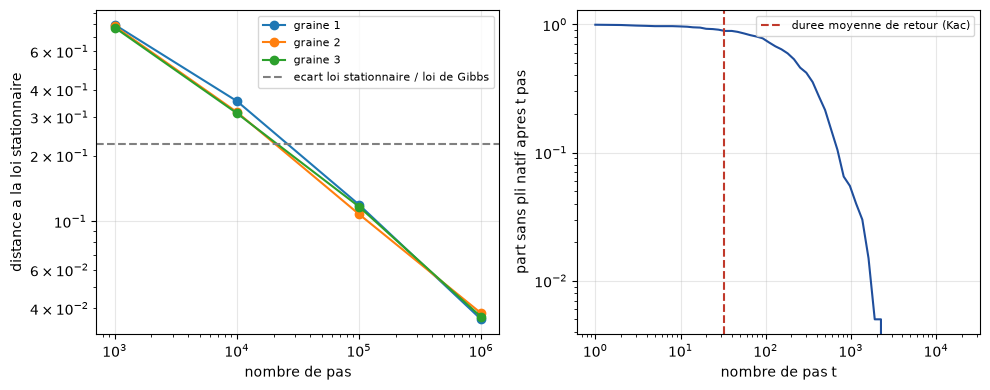

In [18]:
def premiers_passages(cumuls, voisins, e, demarrages, plafond, graine):
    # Temps du premier passage dans le pli natif, depuis un depart tire
    # uniformement parmi les conformations non natives ; plafond + 1 est rendu
    # quand le pli n'est pas atteint en plafond pas
    alea = np.random.default_rng(graine)
    departs = np.where(e > e.min())[0]
    temps = []
    for _ in range(demarrages):
        x = departs[alea.integers(len(departs))]
        for s, tirage in enumerate(alea.random(plafond)):
            x = voisins[x][bisect.bisect(cumuls[x], tirage)]
            if e[x] == e.min():
                temps.append(s + 1)
                break
        else:
            temps.append(plafond + 1)
    return np.array(temps)


PLAFOND = 20000
temps = premiers_passages(cumuls, voisins, e, 200, PLAFOND, 7000)
atteints = temps[temps <= PLAFOND]
print(f'200 demarrages aleatoires hors du pli natif, plafond {PLAFOND} pas : '
      f'{len(atteints)} marches ont trouve le pli natif, {200 - len(atteints)} ne l ont pas trouve')
print(f'parmi celles qui l ont trouve : quartile inferieur {np.quantile(atteints, 0.25):.0f}, '
      f'temps median {np.median(atteints):.0f}, quartile superieur {np.quantile(atteints, 0.75):.0f}, '
      f'plus long {atteints.max()}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
for graine, distances in zip((1, 2, 3), courbes):
    axes[0].loglog(marques, distances, 'o-', label=f'graine {graine}')
axes[0].axhline(0.5 * np.abs(pi - gibbs).sum(), color='0.5', ls='--',
                label='ecart loi stationnaire / loi de Gibbs')
axes[0].set_xlabel('nombre de pas')
axes[0].set_ylabel('distance a la loi stationnaire')
axes[0].legend(fontsize=8)
grille = np.unique(np.logspace(0, math.log10(PLAFOND), 60).astype(int))
axes[1].loglog(grille, [(temps > t).mean() for t in grille], color='#1f4e9c')
axes[1].axvline(1 / pi[natives].sum(), color='#c0392b', ls='--',
                label='duree moyenne de retour (Kac)')
axes[1].set_xlabel('nombre de pas t')
axes[1].set_ylabel('part sans pli natif apres t pas')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


### Lecture du résultat

Les $200$ marches ont trouvé le pli natif avant le plafond. Le temps médian du premier passage est de $246$ pas, le quartile inférieur de $102$, le quartile supérieur de $442$, et le plus long de $2338$. À $32$ pas, durée moyenne de retour au pli natif, plus des trois quarts des marches n'ont pas encore trouvé le pli : les deux nombres ne mesurent pas la même chose. Le premier est un temps de retour, compté depuis le pli lui-même ; le second est un temps d'arrivée, compté depuis un état quelconque.

Le panneau de gauche porte la distance à $\pi$ aux quatre échéances de la simulation ; en pointillé, l'écart entre $\pi$ et la loi de Gibbs. La distance empirique passe sous cet écart entre dix mille et cent mille pas pour les trois graines : à partir de là, la loi empirique est plus proche de $\pi$ que la loi de Gibbs ne l'est ; à dix mille pas, elle en était plus loin. Le panneau de droite porte la part des marches qui n'ont pas encore trouvé le pli selon le temps ; en pointillé vertical, la durée moyenne de retour.

### Exercice 3 — le pli natif devient-il un piège à basse température ?

Tout ce qui précède est mesuré à température $1$. La formule de transition admet une température $T$, qui divise les différences d'énergie : à basse température, les remontées d'énergie deviennent rares.

**À faire.** Calculer $\epsilon$ à $T = 0{,}25$, $0{,}5$, $1$, $2$, $4$ et $16$, et dire ce qui se passe quand $T$ tend vers $0$.

**Indice.** `matrice_transition` et `mesure_stationnaire` prennent `temperature` en argument ; `natives` donne les conformations natives. Pour la limite, comparer le poids du pli natif et celui de ses voisins immédiats dans la formule fermée de la section.

**Étape 1.** Écrire `epsilon_selon_temperature(e, voisins, temperatures)`, qui renvoie $\epsilon$ pour chaque température.
**Étape 2.** L'appliquer aux six températures.
**Étape 3.** Conclure : la part du pli croît-elle indéfiniment quand $T$ diminue, et pourquoi ?


In [19]:
def epsilon_selon_temperature(e, voisins, temperatures):
    # TODO etudiant : pour chaque temperature, calculez la loi stationnaire de
    # la marche a cette temperature et la part de cette loi hors des
    # conformations natives (etapes 1 et 2)
    return None


temperatures = (0.25, 0.5, 1.0, 2.0, 4.0, 16.0)
epsilons = epsilon_selon_temperature(e, voisins, temperatures)
if epsilons is None:
    print('Exercice a completer : epsilon non mesure selon la temperature.')
else:
    for temperature, eps in zip(temperatures, epsilons):
        print(f'T = {temperature:5.2f}   epsilon = {eps:.4f}')


Exercice a completer : epsilon non mesure selon la temperature.


### Un second contrôle : N = 12

Les résultats de la section portent sur une seule séquence. Le bloc qui suit les reprend, sans la simulation ni les temps de passage, pour la séquence `HHHPHPPHPPHP` à $N = 12$ : minimum, composantes des sous-niveaux, minima locaux stricts, loi stationnaire résolue et formule fermée.


In [20]:
# Second controle : la sequence declaree a N = 12, memes mesures qu'a N = 10
voisins_12 = graphe_des_mouvements(marches_12)
e_12 = energie(adj_12, SEQUENCE_12)
natives_12 = np.where(e_12 == e_12.min())[0]
ids_12 = identifiants_plis(marches_12)
niveaux_12 = sous_niveaux(e_12, voisins_12)
P_12, principale_12 = matrice_transition(e_12, voisins_12)
pi_12 = mesure_stationnaire(e_12, voisins_12)
boltee_12 = np.exp(-e_12.astype(float))
# La formule fermee de la loi stationnaire, evaluee pour cette sequence
formule_12 = boltee_12 * np.array([boltee_12[voisins_12[x]].sum() if voisins_12[x] else 0.0
                                   for x in range(len(e_12))])
dans_12 = np.zeros(len(e_12), dtype=bool)
dans_12[principale_12] = True
formule_12 = np.where(dans_12, formule_12, 0.0)
formule_12 = formule_12 / formule_12.sum()
print(f'sequence {SEQUENCE_12} : E* = {int(e_12.min())}, {len(natives_12)} conformations natives, '
      f'{len(set(ids_12[natives_12].tolist()))} pli natif')
print('conformations par energie :', np.bincount(-e_12).tolist()[::-1])
print('composantes de E <= t     :', [l[2] for l in niveaux_12])
print('minima locaux stricts     :', len(minima_locaux(e_12, voisins_12)))
print(f'N = 12, {len(principale_12)} etats dans la composante principale : '
      f'residu du systeme {residu(P_12, pi_12[principale_12]):.3e}, '
      f'residu de la formule {residu(P_12, formule_12[principale_12]):.3e}')
print(f'part des conformations natives : loi stationnaire {pi_12[natives_12].sum():.4f}, '
      f'loi de Gibbs {boltee_12[natives_12].sum() / boltee_12[principale_12].sum():.4f}')


sequence HHHPHPPHPPHP : E* = -4, 2 conformations natives, 1 pli natif
conformations par energie : [2, 104, 1414, 8924, 19629]
composantes de E <= t     : [2, 32, 102, 7, 1]
minima locaux stricts     : 12
N = 12, 30073 etats dans la composante principale : residu du systeme 4.453e-16, residu de la formule 7.986e-17
part des conformations natives : loi stationnaire 0.0032, loi de Gibbs 0.0019


### Lecture du contrôle

À $N = 12$, l'espace compte $30\,073$ conformations. La séquence `HHHPHPPHPPHP` a, comme celle à $N = 10$, un minimum de $-4$, atteint par $2$ conformations d'un même pli. Ses sous-niveaux ont $2$, $32$, $102$, $7$ puis $1$ composantes : même forme, îlots nombreux à basse énergie, fusion au voisinage de zéro. Elle compte $12$ minima locaux stricts. Les deux nombres qui coïncidaient à $N = 10$ en valent ici $102$ et $12$ : la coïncidence n'était pas une identité.

Les résidus de la loi stationnaire sont de $4{,}453 \cdot 10^{-16}$ pour le système et de $7{,}986 \cdot 10^{-17}$ pour la formule fermée : la formule tient à une seconde taille. La part du pli natif est de $0{,}32\,\%$ dans la loi stationnaire et de $0{,}19\,\%$ dans la loi de Gibbs ; elle était de $3{,}12\,\%$ et $1{,}24\,\%$ à $N = 10$.

### En résumé

| Ce qui est établi | Valeur | Contrôle indépendant |
|---|---|---|
| Loi stationnaire | $\pi(x) \propto \exp(-E(x)) \sum_{z \sim x} \exp(-E(z))$ | résidu de l'ordre de $10^{-16}$ à $N = 10$ et à $N = 12$ |
| Écart à la loi de Gibbs | $0{,}2256$ en variation totale | énergie nulle : la loi est proportionnelle au degré |
| Temps passé dans le pli | $0{,}0312$ | $0{,}0309$ à $0{,}0321$ pour trois trajectoires |
| Retour au pli natif | $32{,}0$ pas en moyenne (formule de Kac) | première atteinte médiane $246$ pas : un autre temps, mesuré sur $200$ marches |

Le contre-témoin de la section est l'énergie nulle : là où l'on attend une loi uniforme, la marche favorise déjà les états les mieux connectés.


## 5. Combien de séquences ont un pli unique ?

### Ce que dit Gromov

Le texte compare les séquences à des phrases :

> What Percentige of Polypetride Chains fold? The number of, say, N-long amino acid sequences is 20^N ≈ 10^{1.3N} but the overwhelming majority of polypeptide chains, probably, do not make anything even vaguely reminding proteins. (Random sequences of letters make no sentences in the English language either.)

Dans l'entretien qu'il accorde à la chaîne *Theories of Everything*, Gromov dit la même chose de la part des séquences qui se replient bien, et la laisse ouverte :

> And you can, again, mathematically, almost sure that never. you can find particular sequences which will fall so nicely. And indeed, we don't still know how much they are. If they are exponentially, many of them on the proportion, people argue about that. Most likely, it's exponentially small, but non-zero.

Et, à la fin du même entretien, il range la question parmi celles que la physique seule ne répond pas :

> … why proteins exist, why they fall so fast, and how many of them, and none of them can be answered

La transcription automatique écrit « fall » là où il dit « fold ».

*Sources : texte de 2010, p. 24 — <https://www.ihes.fr/~gromov/wp-content/uploads/2018/08/proteins-crystals-isoper.pdf> ; entretien, 00:06:05–00:06:25 et 00:57:54–00:58:00 — <https://www.youtube.com/watch?v=010zB6EpJYQ>.*

### La méthode

À $N = 10$, il y a $1024$ séquences, et le carnet sait calculer le paysage de chacune. Il le fait pour toutes les séquences de $N = 8$, $10$ et $12$, et dit qu'une séquence a un **pli unique** quand les conformations de son minimum forment un seul pli. La règle est mécanique, et le carnet n'y ajuste rien. Comme contrôle, chaque séquence est comparée à sa lecture renversée, qui doit avoir le même minimum, les mêmes comptes et le même nombre de plis.

Le bloc qui suit effectue ce balayage.


In [21]:
def balaye_sequences(marches, adj, ids):
    # Pour chaque sequence : son energie minimale, le nombre de conformations
    # a cette energie et le nombre de plis qu'elles representent
    n = len(marches[0])
    resultat = np.zeros((1 << n, 3), dtype=np.int64)
    for seq in range(1 << n):
        e = energie(adj, en_sequence(seq, n))
        sol = np.where(e == e.min())[0]
        resultat[seq] = (-int(e.min()), len(sol), len(set(ids[sol].tolist())))
    return resultat


def renverree(seq, n):
    # Numero de la meme sequence lue de droite a gauche
    return int(format(seq, f'0{n}b')[::-1], 2)


for n in (8, 10, 12):
    marches = marches_10 if n == 10 else enumere_marches(n)
    adj = adj_10 if n == 10 else matrice_contacts(marches, n)
    resultat = balaye_sequences(marches, adj, identifiants_plis(marches))
    ecarts = sum(not np.array_equal(resultat[seq], resultat[renverree(seq, n)])
                 for seq in range(1 << n))
    print(f'N = {n} : {int((resultat[:, 2] == 1).sum())} sequences a pli unique sur {1 << n} ; '
          f'ecarts entre une sequence et sa lecture renversee : {ecarts}')
    print('    k   sequences   pli unique    part   une seule conformation native   '
          'plis au minimum (median)')
    for k in range(n + 1):
        rang = [seq for seq in range(1 << n) if bin(seq).count('1') == k]
        sous = resultat[rang]
        print(f'   {k:2d}   {len(rang):9d}   {int((sous[:, 2] == 1).sum()):11d}   '
              f'{(sous[:, 2] == 1).mean():.4f}   {int((sous[:, 1] == 1).sum()):31d}   '
              f'{np.median(sous[:, 2]):24.1f}')
    regle = [seq for seq in range(1 << n)
             if resultat[seq, 2] == 1 and bin(seq).count('1') == n // 2][0]
    print(f'   premiere sequence a pli unique avec autant de H que de P : {en_sequence(regle, n)}, '
          f'E* = {-int(resultat[regle, 0])}, {int(resultat[regle, 1])} conformation(s) native(s)')
    if n in (10, 12):
        declaree = sum(1 << i for i, lettre in enumerate(SEQUENCE_10 if n == 10 else SEQUENCE_12)
                       if lettre == 'H')
        print(f'   c est la sequence declaree par le carnet : {regle == declaree}')


N = 8 : 7 sequences a pli unique sur 256 ; ecarts entre une sequence et sa lecture renversee : 0
    k   sequences   pli unique    part   une seule conformation native   plis au minimum (median)
    0           1             0   0.0000                                 0                      272.0
    1           8             0   0.0000                                 0                      272.0
    2          28             0   0.0000                                 0                      272.0
    3          56             0   0.0000                                 0                       30.0
    4          70             5   0.0714                                 0                        6.0
    5          56             2   0.0357                                 0                        6.5
    6          28             0   0.0000                                 0                        8.5
    7           8             0   0.0000                                 0                 

N = 10 : 6 sequences a pli unique sur 1024 ; ecarts entre une sequence et sa lecture renversee : 0
    k   sequences   pli unique    part   une seule conformation native   plis au minimum (median)
    0           1             0   0.0000                                 0                     2034.0
    1          10             0   0.0000                                 0                     2034.0
    2          45             0   0.0000                                 0                     2034.0
    3         120             0   0.0000                                 0                       90.5
    4         210             2   0.0095                                 0                       18.0
    5         252             4   0.0159                                 0                       11.5
    6         210             0   0.0000                                 0                       13.0
    7         120             0   0.0000                                 0               

N = 12 : 87 sequences a pli unique sur 4096 ; ecarts entre une sequence et sa lecture renversee : 0
    k   sequences   pli unique    part   une seule conformation native   plis au minimum (median)
    0           1             0   0.0000                                 0                    15037.0
    1          12             0   0.0000                                 0                    15037.0
    2          66             0   0.0000                                 0                    15037.0
    3         220             0   0.0000                                 0                      401.0
    4         495             4   0.0081                                 0                       68.0
    5         792            20   0.0253                                 0                       28.0
    6         924            30   0.0325                                 0                       21.0
    7         792            18   0.0227                                 0              

### Lecture du résultat

Les séquences à pli unique sont $7$ sur $256$ à $N = 8$, soit $2{,}7\,\%$ ; $6$ sur $1024$ à $N = 10$, soit $0{,}6\,\%$ ; $87$ sur $4096$ à $N = 12$, soit $2{,}1\,\%$. Trois tailles ne tranchent rien sur une décroissance exponentielle : la part n'est pas décroissante. La colonne « une seule conformation native » est nulle partout, comme l'imposait la section 1.

Il n'y a aucun pli unique à moins de quatre résidus $H$ : il faut assez d'hydrophobes pour qu'un arrangement soit seul à réaliser le maximum. À $k = 0$, la médiane du nombre de plis au minimum vaut le nombre total de plis, $272$, $2034$ et $15\,037$ : toutes les conformations sont d'énergie nulle, et le minimum est tout l'espace.

La première séquence à pli unique qui compte autant de $H$ que de $P$ est `HHPHPPHPPH` à $N = 10$ : c'est la séquence déclarée des sections 3 et 4. À $N = 12$, c'est `HHHPHPPHPPHP`, celle du second contrôle.

### En résumé

| Taille | Séquences | À pli unique | Part | Contrôle |
|---|---|---|---|---|
| $N = 8$ | $256$ | $7$ | $2{,}7\,\%$ | lecture renversée : $0$ écart |
| $N = 10$ | $1024$ | $6$ | $0{,}6\,\%$ | lecture renversée : $0$ écart |
| $N = 12$ | $4096$ | $87$ | $2{,}1\,\%$ | lecture renversée : $0$ écart |

Le contre-témoin de la section est la colonne « une seule conformation native », nulle partout : un pli unique n'est pas une conformation unique, et le compte des conformations natives ne peut pas servir de mesure.


## 6. Statut de ce que le carnet établit

**Mesuré dans ce carnet.**

- L'espace $X$ compte $4067$ conformations à $N = 10$ et $30\,073$ à $N = 12$, comptées par deux algorithmes indépendants ; il a $2034$ et $15\,037$ plis, et $|X| = 2 \times (\text{plis}) - 1$ à chaque taille mesurée.
- Une chaîne tout hydrophobe atteint le plancher de $N + 1 - 2\sqrt{N}$ de $N = 4$ à $N = 16$ ; à $N = 10$, aucune des $1024$ séquences ne dépasse la plus petite de ses deux bornes.
- Pour la séquence déclarée, $E^* = -4$, $2$ conformations natives d'un seul pli, $92$ minima locaux stricts dont $90$ hors du pli natif, et des sous-niveaux à $2$, $24$, $92$, $3$, $1$ composantes.
- La loi stationnaire de la marche vaut $\pi(x) \propto \exp(-E(x)) \sum_{z \sim x} \exp(-E(z))$ : elle diffère de la loi de Gibbs de $0{,}2256$ en variation totale, et place $3{,}12\,\%$ de sa masse dans le pli natif, soit $\epsilon = 0{,}9688$.
- Le temps moyen de retour au pli natif est de $32{,}0$ pas, et le temps médian de première atteinte, depuis un état quelconque, de $246$ pas.
- Les séquences à pli unique sont $2{,}7\,\%$ à $N = 8$, $0{,}6\,\%$ à $N = 10$ et $2{,}1\,\%$ à $N = 12$.

**Cité, non redémontré.** La formulation du repliement comme minimum sur un espace de configuration, puis comme marche biaisée, et la définition de l'état replié par $\epsilon$, viennent du texte de Gromov de 2010. Le nombre de chaînes qui se replient, et la question de savoir si leur part est exponentiellement petite, sont saisis par lui et laissés ouverts. L'isopérimétrie du texte porte sur d'autres objets — les globules rouges, les micelles, les cristaux — et n'est pas utilisée ici : les deux bornes de la section 2 sont démontrées dans le carnet.

**Ouvert.** Pourquoi les protéines se replient vite, alors que le nombre de minima locaux croît probablement de façon exponentielle. Quelle part de séquences a un pli unique, et si cette part décroît exponentiellement : trois tailles ne disent rien. Ce que devient le paysage sur un réseau à trois dimensions. Et ce que ces calculs disent d'une protéine réelle, dont l'énergie n'est pas une somme de termes de paire.


### Limites

Le modèle est **petit**. Les chaînes comptent de $3$ à $16$ résidus ; Gromov donne pour une chaîne protéique une longueur typique de $100$ à $300$ résidus. Les tailles où l'énumération complète est possible s'arrêtent vers $N = 12$ pour l'espace entier : ce que le carnet mesure n'est pas extrapolé.

L'énergie est **additive**. Chaque paire de résidus hydrophobes en contact vaut un, et les autres paires zéro : c'est exactement ce que le texte de Gromov dément d'une protéine réelle. Les bornes de la section 2 valent pour cette énergie, et pour elle seule.

La marche est **à temps discret**. C'est l'écart à la loi de Gibbs qui en vient : en temps continu, avec des taux symétriques entre voisins et une horloge ralentie dans les vallées, la loi stationnaire serait la loi de Gibbs. Le carnet a retenu le temps discret parce que la formule fermée s'y démontre en deux lignes.

L'étude est **ponctuelle**. Une séquence en détail, une en contrôle ; trois trajectoires simulées ; deux cents temps de passage.

Enfin, le modèle n'est pas une protéine : réseau plan, deux espèces de résidus, aucune géométrie. Ce qu'il établit, il l'établit de lui-même.


## Références

- Gromov, M., **Crystals, Proteins, Stability and Isoperimetry**, texte du 3 août 2010, mis en ligne par l'IHES. <https://www.ihes.fr/~gromov/wp-content/uploads/2018/08/proteins-crystals-isoper.pdf>. Copie archivée dans le gisement partagé : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Biology\2010 - Gromov - Crystals, Proteins, Stability and Isoperimetry (ihes.fr, OA).pdf`. Passages utilisés : section 5, p. 14 (forme repliée, noyau hydrophobe, longueur des chaînes) ; section 6, p. 21–24 (espace de configuration, minima locaux, marche biaisée, état replié et ε, part des chaînes qui se replient, énergie non additive). Son isopérimétrie concerne les globules rouges, les micelles et les cristaux : la borne sur réseau de la section 2 est celle du carnet.
- Gromov, M., entretien **The Math That Life Is (Still) Missing**, chaîne *Theories of Everything*. <https://www.youtube.com/watch?v=010zB6EpJYQ>. Transcription automatique archivée dans le gisement partagé : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Biology\2026 - Jaimungal & Gromov - The Math That Life Is (Still) Missing (Theories of Everything, transcription YouTube 010zB6EpJYQ).txt`. Passages utilisés : 00:06:05–00:06:25, 00:57:44–00:57:52 et 00:57:54–00:58:00 ; « fall » y transcrit « fold ».
- [Structures-01](Structures-01-Liaisons-Hydrogene-Squelette-Proteique-Python.ipynb), feuille précédente du pli : la géométrie de la liaison hydrogène et du squelette.


## Pour aller plus loin

- La feuille suivante du pli prend le **repliement d'ARN** : [Structures-03 — ARN circulaire et repliement en paires](Structures-03-ARN-Circulaire-Repliement-Paires-Python.ipynb) transporte la récurrence de comptage de Nussinov sur le cercle et la confronte à deux contrôles indépendants ; la minimisation d'une énergie y est annoncée comme la feuille d'après.
- Quand l'espace devient trop grand pour être parcouru en entier, chercher sans tout énumérer devient le problème : c'est le sujet de la série [Search](../../Search/README.md) — exploration systématique, optimisation locale (le recuit simulé y est la marche biaisée de la section 4, à température décroissante), métaheuristiques.
- La sous-série sœur [Dynamiques](../Dynamiques/README.md) pose, pour les populations, la question symétrique de la section 4 : ses feuilles de recherche annoncées prévoient une simulation stochastique de Gillespie, dont la moyenne doit retrouver l'équation déterministe. Ici, la loi de long terme est calculée exactement, et trois trajectoires simulées s'en approchent.

[↑ Retour au sommaire de la série](../README.md)
